# 05b. Atmospheric and land initialization benefits for subseasonal 2-m temperature: weekly benefits and skill

Weekly means (weeks 1-8 = lead days 1-7, ..., 50-56) of the benefits $\Delta S_A = S_{10} - S_{00}$, $\Delta S_L = S_{11} - S_{10}$ and the total, with their 2.5-97.5 % paired-bootstrap intervals, and the absolute pattern ACC of each role. Design, inputs and method: `05a`.

**The 05a-05c series** (DART initialization benefits for subseasonal 2-m temperature; each notebook reads the data it needs, computes, saves, then plots): `05a` the three-panel figure on daily running means; `05b` weekly benefits with bootstrap intervals and absolute skill; `05c` gridpoint-ACC benefit maps (DJF, JJA and both seasons in one figure). Settings: `InitBenefitSettings` in `configs/hind_lead_eval_cases.py`; products: `util/init_benefit_workflow.py`; methods: `util/init_benefit.py`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/init_benefit/init_benefit_curves_weekly.csv`; figures `init_benefit_weekly_<BIAS>_<SET>.png`, `init_skill_<BIAS>_<SET>.png` in `figure/hind_lead_eval/init_benefit/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction, ELM layer thicknesses
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
}
# the experiments of each role are set by the settings (roles); CONFIGS gives their case names

CASE_OVERRIDES = {}     # changes to the InitBenefitSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"max_members": 3}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import InitBenefitSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.init_benefit_workflow import InitBenefitCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = InitBenefitCase(InitBenefitSettings(paths=paths, **{**CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit
[MEMBERS] DJF E00: 20: EN01, EN02, EN03, EN04, EN05, EN06, EN07, EN08, EN09, EN10, EN11, EN12, EN13, EN14, EN15, EN16, EN17, EN18, EN19, EN20
[MEMBERS] DJF E10: 20: EN01, EN03, EN04, EN07, EN08, EN09, EN10, EN14, EN17, EN18, EN20, EN21, EN25, EN26, EN28, EN31, EN35, EN36, EN37, EN40
[MEMBERS] DJF E01: 20: EN01, EN03, EN04, EN07, EN08, EN09, EN10, EN14, EN17, EN18, EN20, EN21, EN25, EN26, EN28, EN31, EN35, EN36, EN37, EN40
[MEMBERS] DJ

## 4. Read input

The roles and the seasons in which every role's members are post-processed. The daily member values, observations and climatologies on the region's box (`daily_*.nc`, `daily_ref_*.nc`) are read when the scores must be computed.

In [4]:
display(case.role_table())
print(f"[SEASONS] {case.seasons}; season sets: {case.sets}")

,role,config,atmosphere,land
0,E00,HYB_BASE,ERA5+DART pert.,DATM-forced
1,E10,DA_ATM,DART,DATM-forced
2,E01,DA_LND,ERA5,DART
3,E11,DA_COUPLED,DART,DART


           ready     members    
season       DJF JJA     DJF JJA
config                          
DA_ATM        80  80      80  80
DA_COUPLED    80  80      80  80
DA_LND        80  80      80  80
HYB_BASE      80  80      80  80
[SEASONS] usable (every role ready): ['DJF', 'JJA']
[SEASONS] ['DJF', 'JJA']; season sets: {'DJF': ['DJF'], 'JJA': ['JJA'], 'ALL': ['DJF', 'JJA']}


## 5. Process and save

Skill and contrast curves on weekly means: panel (b) per bias treatment and season set, panel (c), with paired-bootstrap intervals (`init_benefit_curves_weekly.csv`). Shown: the contrasts, all seasons.

In [5]:
table = case.curves("weekly")
display(table[(table.kind == "contrast") & (table.set == "ALL")]
        .pivot_table(index=["panel", "bias", "name"], columns="step", values="value", sort=False).round(3))

[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_curves_weekly.csv: built with other settings, recomputing


[DAILY] E00 HYB_BASE DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E10 DA_ATM DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E01 DA_LND DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E11 DA_COUPLED DJF: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


[DAILY] E00 HYB_BASE JJA: {'init': 4, 'member': 20, 'lead': 56, 'lat': 30, 'lon': 360}


... (3 outputs left out)

[SCORES] weekly DJF


[SCORES] weekly JJA


[SCORES] weekly ALL
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/init_benefit/init_benefit_curves_weekly.csv


step                               1      2      3      4      5      6  \
panel        bias name                                                    
ERA5         amip atmosphere   0.335  0.173  0.095  0.178  0.172  0.156   
                  land         0.009  0.020  0.014 -0.087 -0.072 -0.151   
                  interaction  0.010  0.022 -0.064 -0.064 -0.085 -0.156   
                  total        0.334  0.171  0.172  0.156  0.185  0.161   
             none atmosphere   0.257  0.130  0.048  0.154  0.161  0.134   
                  land        -0.012  0.009  0.004 -0.050 -0.036 -0.102   
                  interaction -0.005  0.013 -0.055 -0.015 -0.037 -0.125   
                  total        0.250  0.127  0.107  0.120  0.161  0.156   
model member amip atmosphere   0.434  0.487  0.319  0.194  0.140  0.126   
                  land         0.009  0.007  0.003  0.006  0.000  0.006   
                  interaction  0.012  0.036  0.078  0.049 -0.003 -0.000   
                  total        0.432  0.459  0.243  0.152  0.143  0.133   

step                               7      8  
panel        bias name                       
ERA5         amip atmosphere   0.294  0.085  
                  land         0.121  0.036  
                  interaction  0.017 -0.013  
                  total        0.398  0.133  
             none atmosphere   0.166  0.060  
                  land         0.041  0.021  
                  interaction -0.040 -0.031  
                  total        0.247  0.112  
model member amip atmosphere   0.179  0.123  
                  land         0.041  0.010  
                  interaction  0.019 -0.028  
                  total        0.201  0.161

## 6. Plot and show

Weekly benefits with intervals (three panels as `05a`) and the absolute skill of every role.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_amip_DJF.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_amip_DJF.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_none_DJF.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_none_DJF.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_amip_JJA.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_amip_JJA.png


... (2 outputs left out)

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_amip_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_benefit_weekly_none_ALL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/init_benefit/init_skill_none_ALL.png


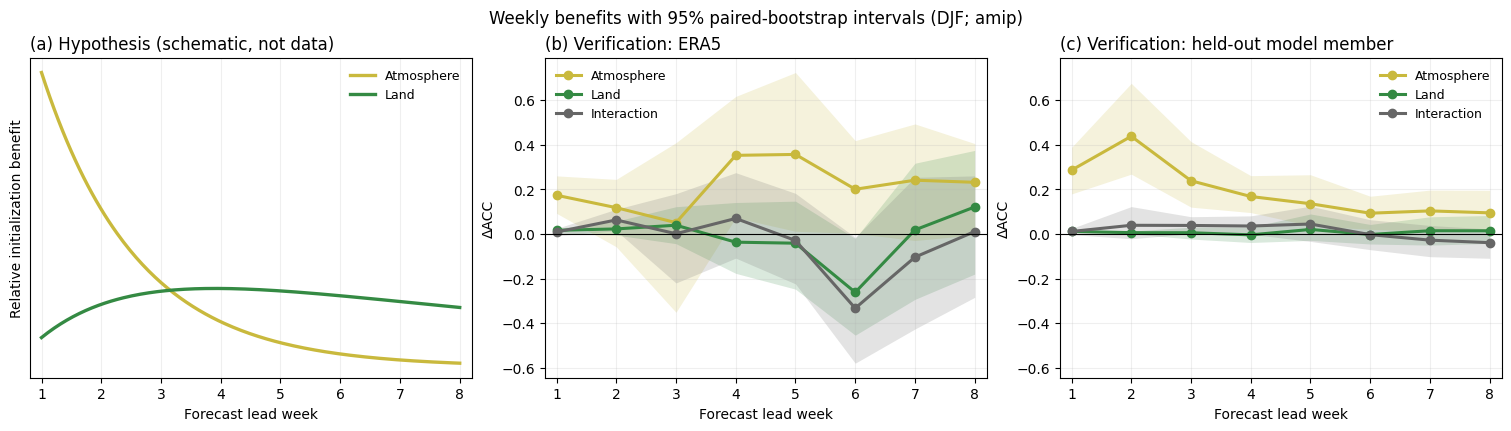

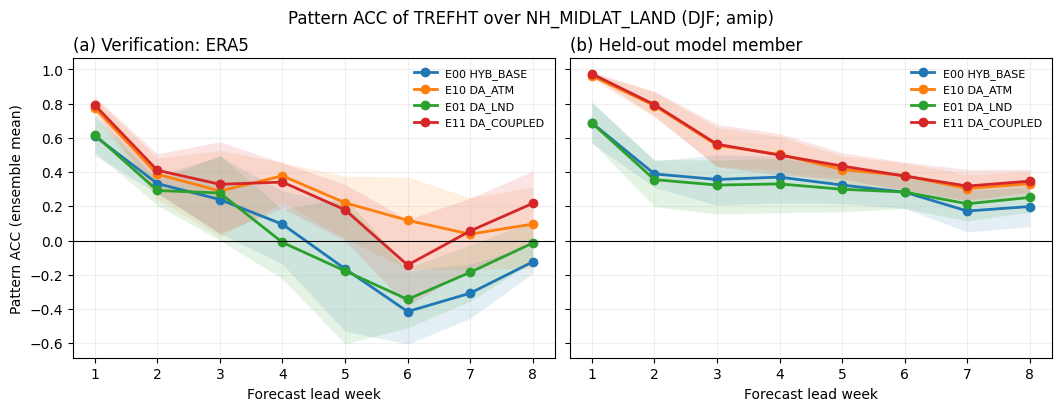

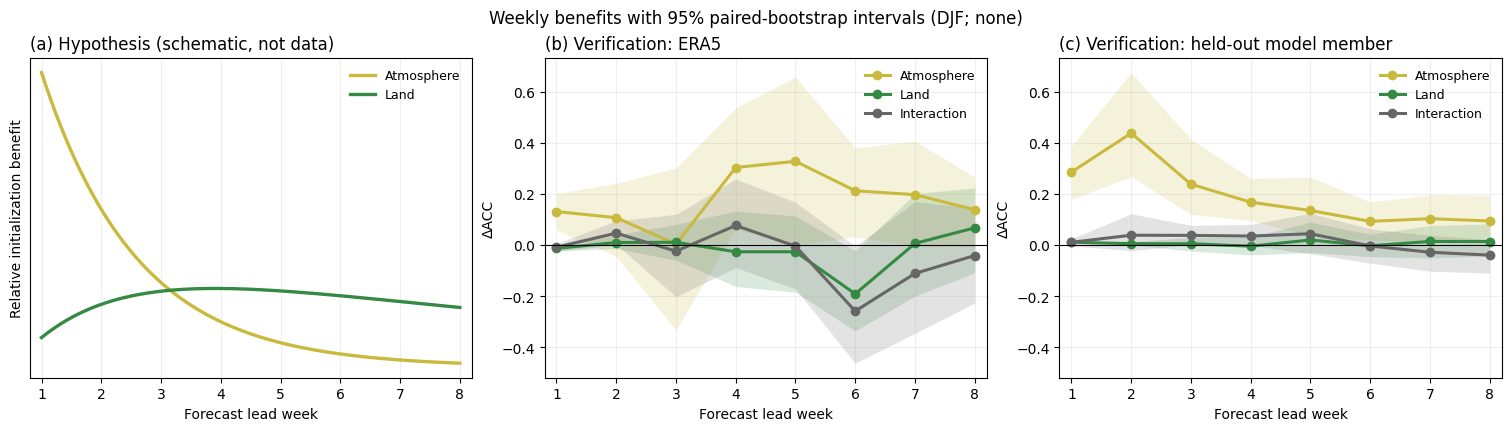

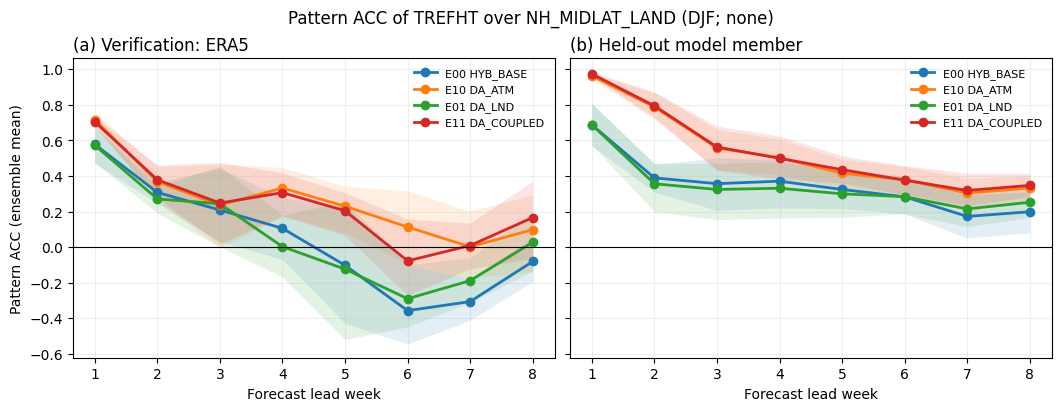

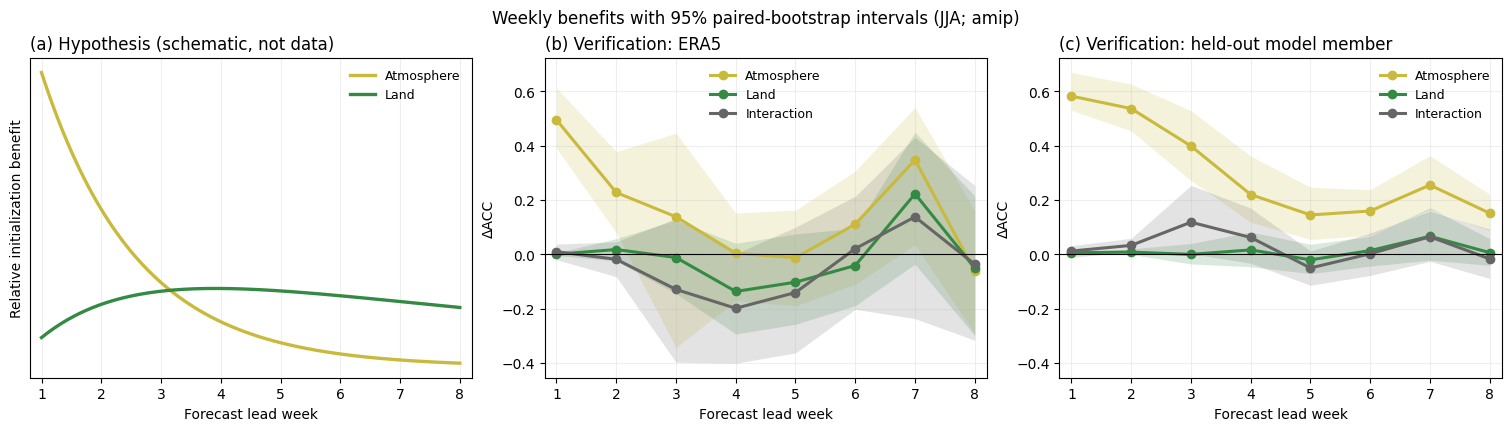

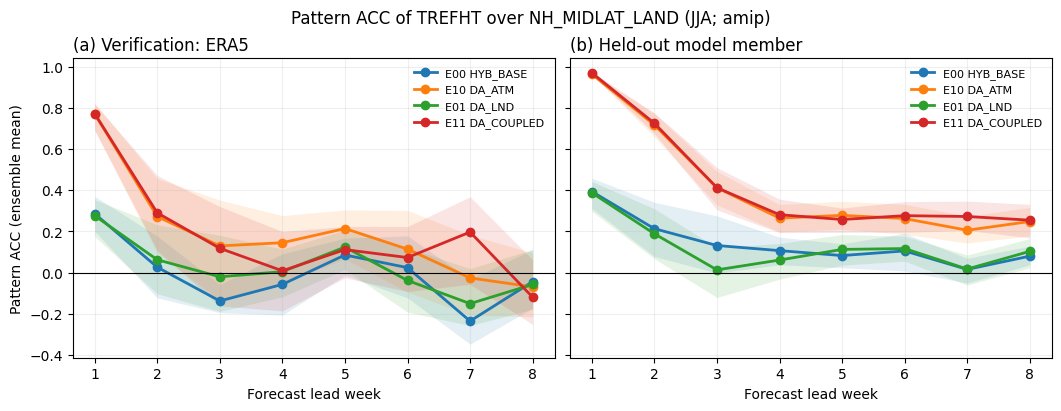

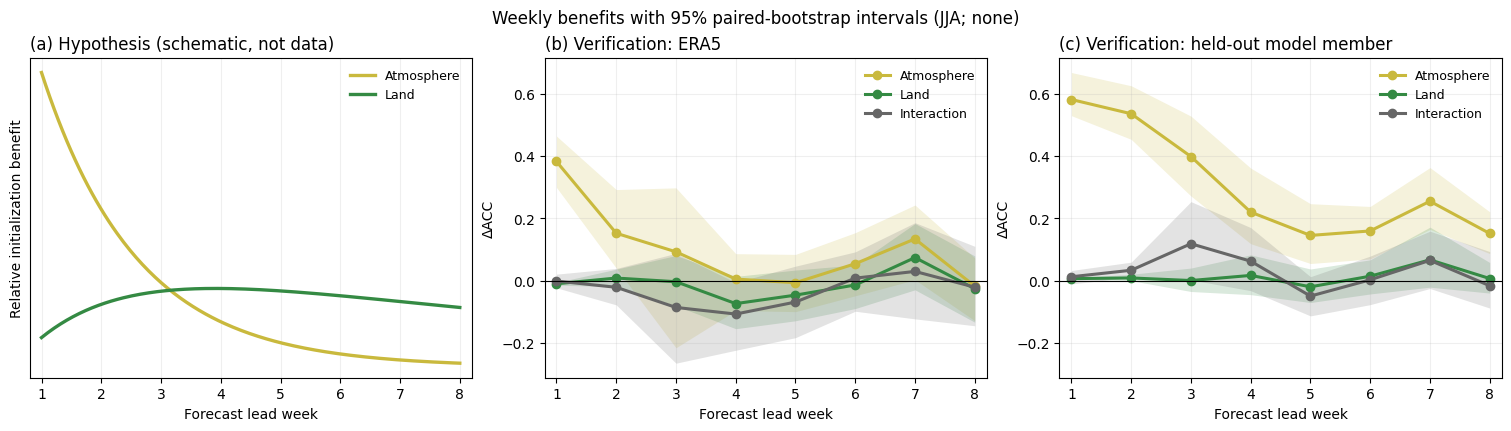

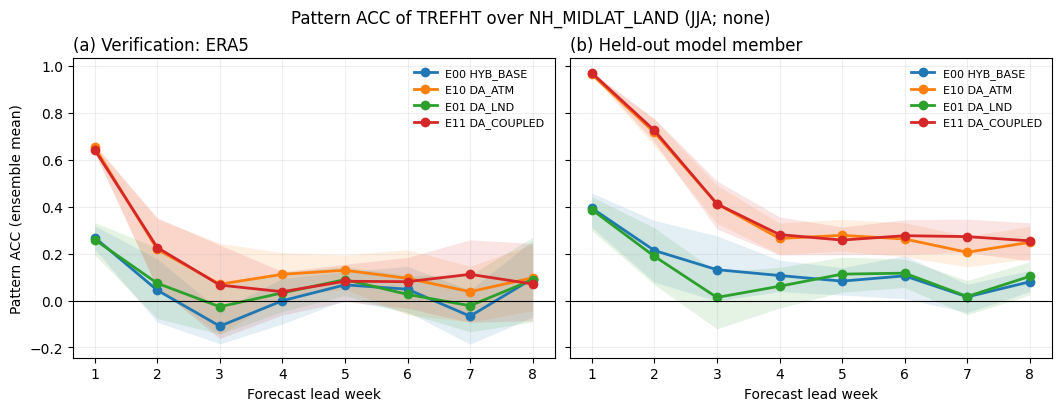

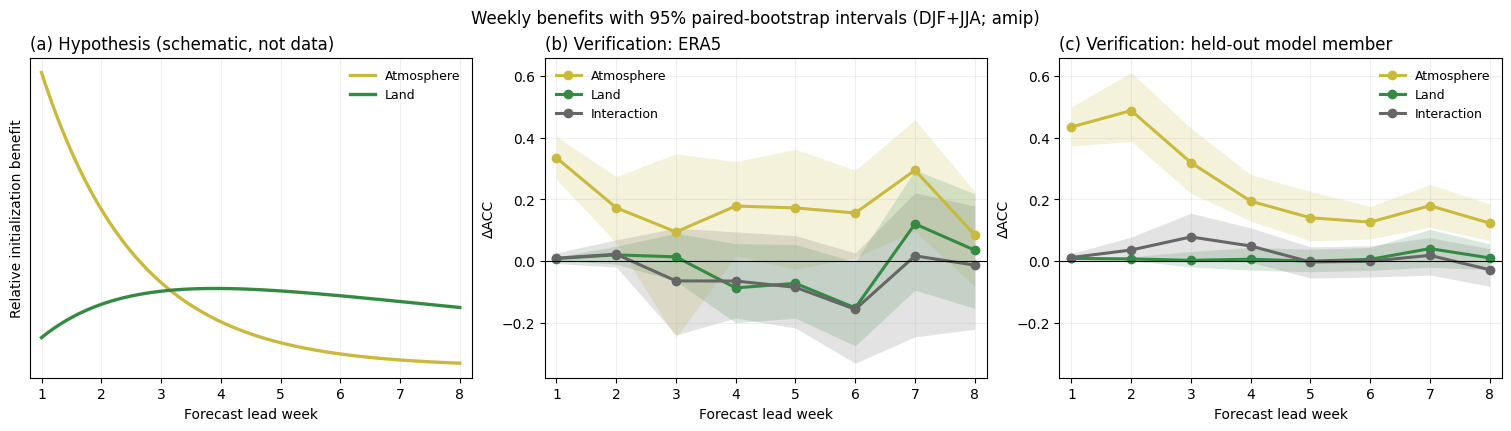

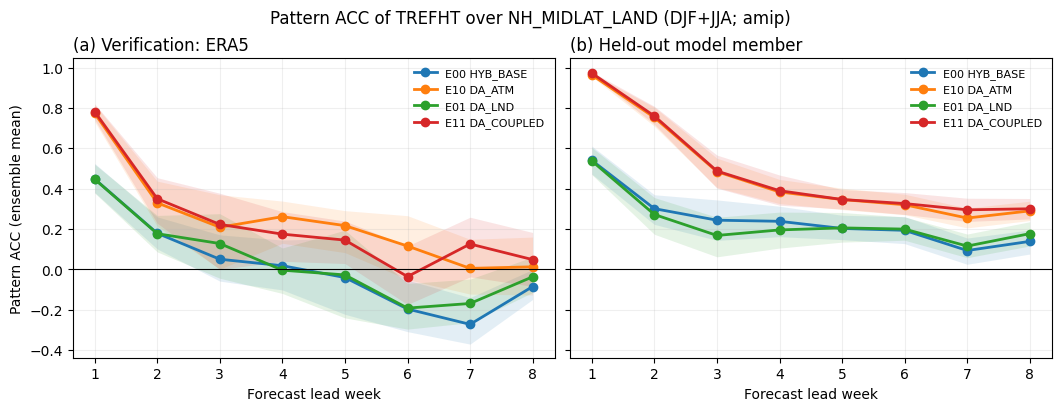

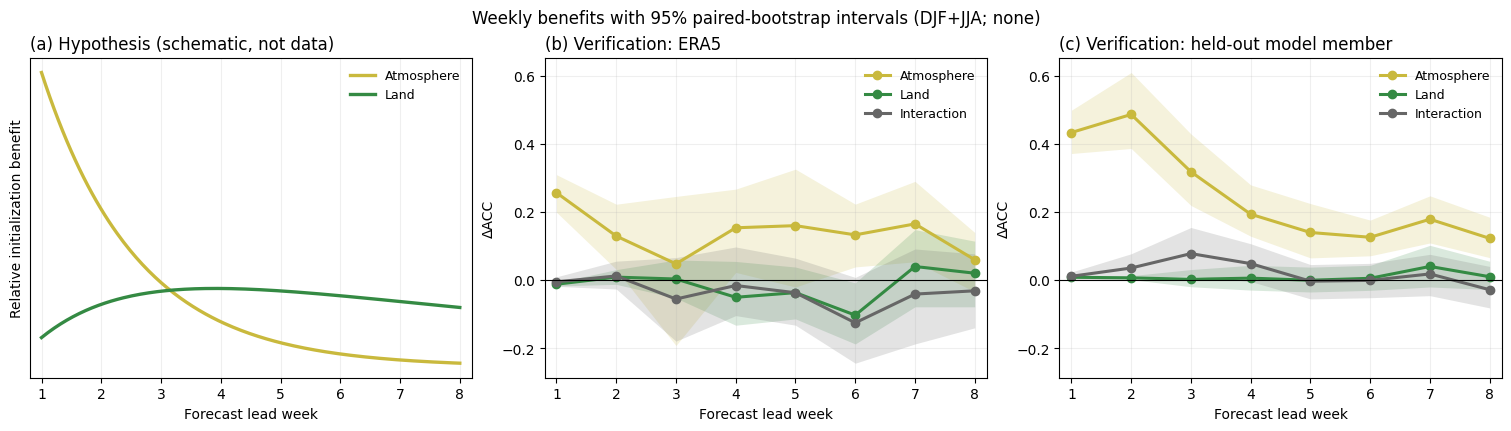

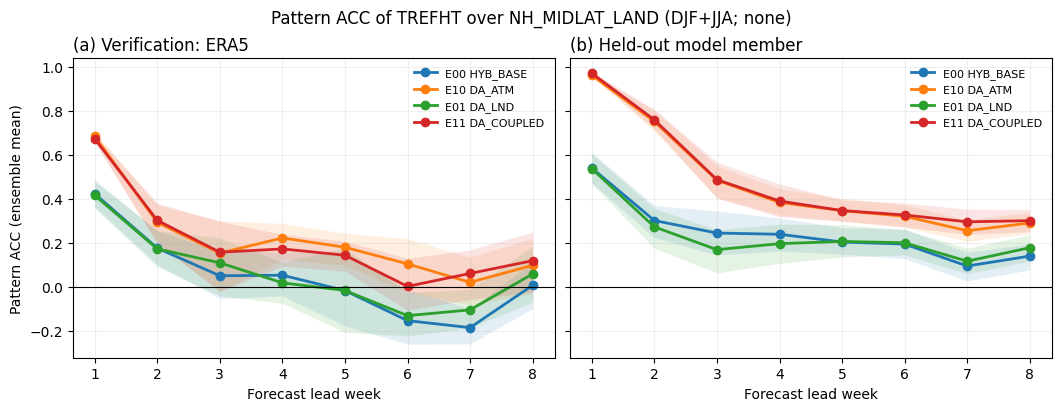

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.init_benefit import plot_benefit_figure, plot_skill_curves

names = [n for n in ("atmosphere", "land", "interaction") if n in cfg.contrasts]
for name, set_seasons in case.sets.items():
    span = "+".join(set_seasons)
    pc = case.panel(table, "model member", name)
    for b in cfg.biases:
        pb = case.panel(table, "ERA5", name, b)
        save(plot_benefit_figure(case.weeks, pb, pc, names=names,
                                 title=f"Weekly benefits with 95% paired-bootstrap intervals ({span}; {b})"),
             f"init_benefit_weekly_{b}_{name}.png")
        save(plot_skill_curves(case.weeks, pb, pc, case.roles, STYLE_MAP,
                               title=f"Pattern ACC of {cfg.variable} over {cfg.region['name']} ({span}; {b})"),
             f"init_skill_{b}_{name}.png")